# ANN Class-Imbalance Experiments

This notebook compares a baseline ANN with SMOTE, random undersampling, and random oversampling. The experiment uses one stratified partition, the same preprocessing and ANN settings for every strategy, and separate validation-based threshold selection and untouched test evaluation.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

### Reproducibility settings

The fixed random seed and threaded/PyTorch data generator keep model initialization and shuffled training batches consistent across the four strategies.

In [2]:
RANDOM_STATE = 42
BATCH_SIZE = 32
LEARNING_RATE = 0.001
EPOCHS = 100

## 2. Dataset loading and initial inspection

In [3]:
def drive_to_direct_url(link):
    patterns = (r"/file/d/([a-zA-Z0-9_-]+)", r"id=([a-zA-Z0-9_-]+)", r"/open\?id=([a-zA-Z0-9_-]+)")
    for pattern in patterns:
        match = re.search(pattern, link)
        if match:
            return f"https://drive.google.com/uc?id={match.group(1)}"
    raise ValueError("Invalid Google Drive link")

In [4]:
local_dataset = Path("cleaned_diabetes.csv")
if not local_dataset.exists():
    local_dataset = Path("diadb-training/cleaned_diabetes.csv")

if local_dataset.exists():
    df = pd.read_csv(local_dataset)
else:
    drive_url = "https://drive.google.com/file/d/1AxchD_W4q0d9lXBOi2gyqunl_TmH3ktm/view?usp=sharing"
    df = pd.read_csv(drive_to_direct_url(drive_url))

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (5261, 13)


,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,17.79,0,0,0,0,0,No


## 4. Train, validation, and test splitting

The split produces approximately 68% training, 12% validation, and 20% test data. All class-balanced samples are resampled only inside the training strategy; validation and test data remain in their original distributions.

In [5]:
X = df.drop(columns="diabetic")
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["diabetic"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE
)

print(f"Training: {len(y_train):,}; validation: {len(y_val):,}; test: {len(y_test):,}")
print(f"Label mapping: {dict(enumerate(label_encoder.classes_))} (positive class = 1)")

Training: 3,576; validation: 632; test: 1,053
Label mapping: {0: 'No', 1: 'Yes'} (positive class = 1)


## 5. Class distribution analysis

In [6]:
def class_counts(labels):
    counts = pd.Series(labels).value_counts().reindex([0, 1], fill_value=0)
    return {label_encoder.classes_[i]: int(counts[i]) for i in (0, 1)}

In [7]:
original_train_distribution = class_counts(y_train)
print("Training:", original_train_distribution)
print("Validation:", class_counts(y_val))
print("Test:", class_counts(y_test))

Training: {'No': 3343, 'Yes': 233}
Validation: {'No': 591, 'Yes': 41}
Test: {'No': 985, 'Yes': 68}


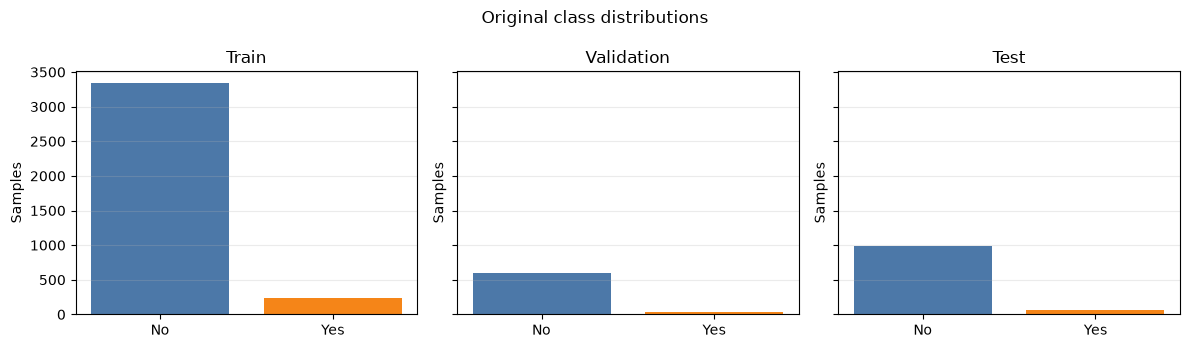

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (name, labels) in zip(axes, [("Train", y_train), ("Validation", y_val), ("Test", y_test)]):
    counts = pd.Series(labels).value_counts().reindex([0, 1], fill_value=0)
    ax.bar(label_encoder.classes_, counts.values, color=["#4C78A8", "#F58518"])
    ax.set(title=name, ylabel="Samples")
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("Original class distributions")
fig.tight_layout()
plt.show()

## 3. Preprocessing and feature preparation

The target is encoded once. The stratified split is created before each strategy; preprocessing is then fitted only on the training fold to prevent validation/test information from entering feature scaling or categorical encoding.

In [9]:
def build_preprocessor(features):
    numeric = features.select_dtypes(include="number").columns
    categorical = features.select_dtypes(exclude="number").columns
    return ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])

In [10]:
def make_loader(features, labels, shuffle, generator=None):
    if hasattr(features, "toarray"):
        features = features.toarray()
    features = np.asarray(features, dtype=np.float32)
    labels = np.asarray(labels, dtype=np.float32).reshape(-1, 1)
    dataset = TensorDataset(torch.from_numpy(features), torch.from_numpy(labels))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)

In [11]:
torch.set_num_threads(1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

Training device: cpu


In [12]:
def build_model(input_features):
    return nn.Sequential(
        nn.Linear(input_features, 64),
        nn.ReLU(),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Linear(32, 1),
    ).to(device)

In [13]:
def predict(model, loader):
    model.eval()
    y_true, y_pred, y_prob = [], [], []
    with torch.no_grad():
        for features, labels in loader:
            probabilities = torch.sigmoid(model(features.to(device)).squeeze(1))
            predictions = (probabilities >= 0.5).int()
            y_true.extend(labels.numpy().ravel())
            y_pred.extend(predictions.cpu().numpy().ravel())
            y_prob.extend(probabilities.cpu().numpy().ravel())
    return np.asarray(y_true, dtype=int), np.asarray(y_pred, dtype=int), np.asarray(y_prob)

In [14]:
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
    }

## 6. Imbalance handling

SMOTE creates synthetic minority observations, random undersampling removes majority observations, and random oversampling duplicates minority observations. These alternatives test both synthetic versus duplicate minority examples and a much smaller training set versus class equality.

Sampling is applied only after training preprocessing and exclusively to the training set. Resampling validation or test data would alter the population being measured and create leakage.

In [15]:
samplers = {
    "Baseline ANN": None,
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
    "Random Undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "Random Oversampling": RandomOverSampler(random_state=RANDOM_STATE),
}
results = {}
comparison_rows = []

In [16]:
def prepare_strategy_data(sampler):
    preprocessor = build_preprocessor(X_train)
    X_train_processed = preprocessor.fit_transform(X_train)
    X_val_processed = preprocessor.transform(X_val)
    X_test_processed = preprocessor.transform(X_test)
    if sampler is None:
        X_resampled, y_resampled = X_train_processed, y_train
    else:
        X_resampled, y_resampled = sampler.fit_resample(X_train_processed, y_train)
    return X_train_processed, X_val_processed, X_test_processed, X_resampled, y_resampled

In [17]:
def set_run_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        torch.cuda.manual_seed_all(seed)
    return torch.Generator().manual_seed(seed)

## 7. ANN training and default-threshold evaluation

The baseline and sampling strategies use the same 64-32 hidden-layer architecture, ReLU activations, Adam optimizer, learning rate, batch size, and 100 epochs. BCE-with-logits loss is appropriate for the binary label; no additional regularization or early stopping is added because it was not present in the original experiment.

In [18]:
def train_model(X_resampled, y_resampled, input_features, seed):
    generator = set_run_seed(seed)
    train_loader = make_loader(X_resampled, y_resampled, shuffle=True, generator=generator)
    model = build_model(input_features)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_losses = []

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        for features, labels in train_loader:
            features, labels = features.to(device), labels.to(device)
            loss = criterion(model(features), labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * features.size(0)
        epoch_loss = running_loss / len(train_loader.dataset)
        train_losses.append(epoch_loss)
        if (epoch + 1) % 20 == 0 or epoch == 0:
            print(f"Epoch [{epoch + 1}/{EPOCHS}], Train Loss: {epoch_loss:.4f}")
    return model, train_losses

In [19]:
def run_strategy(strategy_name, sampler):
    print(f"\n### {strategy_name}")
    X_train_processed, X_val_processed, X_test_processed, X_resampled, y_resampled = prepare_strategy_data(sampler)
    resampled_distribution = class_counts(y_resampled)
    print("Original train distribution:", original_train_distribution)
    print("Resampled train distribution:", resampled_distribution)

    model, train_losses = train_model(
        X_resampled, y_resampled, X_train_processed.shape[1], RANDOM_STATE
    )
    val_loader = make_loader(X_val_processed, y_val, shuffle=False)
    test_loader = make_loader(X_test_processed, y_test, shuffle=False)
    val_true, val_pred, val_prob = predict(model, val_loader)
    test_true, test_pred, test_prob = predict(model, test_loader)
    validation_metrics = calculate_metrics(val_true, val_pred, val_prob)
    test_metrics = calculate_metrics(test_true, test_pred, test_prob)

    results[strategy_name] = {
        "model": model,
        "train_losses": train_losses,
        "y_val_true": val_true,
        "y_val_prob": val_prob,
        "y_true": test_true,
        "y_pred": test_pred,
        "y_prob": test_prob,
        "confusion_matrix": confusion_matrix(test_true, test_pred, labels=[0, 1]),
        "validation_metrics": validation_metrics,
        "test_metrics": test_metrics,
        "original_distribution": original_train_distribution,
        "resampled_distribution": resampled_distribution,
    }
    comparison_rows.append({
        "Strategy": strategy_name,
        "Original train distribution": original_train_distribution,
        "Resampled train distribution": resampled_distribution,
        **test_metrics,
    })
    print("Validation metrics:", {k: round(v, 4) for k, v in validation_metrics.items()})
    print("Test metrics:", {k: round(v, 4) for k, v in test_metrics.items()})

### 4.1 Baseline ANN

In [20]:
run_strategy("Baseline ANN", samplers["Baseline ANN"])


### Baseline ANN


Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 3343, 'Yes': 233}


Epoch [1/100], Train Loss: 0.3215


Epoch [20/100], Train Loss: 0.1507


Epoch [40/100], Train Loss: 0.1319


Epoch [60/100], Train Loss: 0.1158


Epoch [80/100], Train Loss: 0.1003


Epoch [100/100], Train Loss: 0.0869
Validation metrics: {'Accuracy': 0.9288, 'Precision': 0.4231, 'Recall': 0.2683, 'F1-score': 0.3284, 'ROC-AUC': 0.7686, 'PR-AUC': 0.2602}
Test metrics: {'Accuracy': 0.9297, 'Precision': 0.4286, 'Recall': 0.2647, 'F1-score': 0.3273, 'ROC-AUC': 0.8082, 'PR-AUC': 0.3367}


### 4.2 SMOTE

In [21]:
run_strategy("SMOTE", samplers["SMOTE"])


### SMOTE
Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 3343, 'Yes': 3343}


Epoch [1/100], Train Loss: 0.4655


Epoch [20/100], Train Loss: 0.2248


Epoch [40/100], Train Loss: 0.1458


Epoch [60/100], Train Loss: 0.1016


Epoch [80/100], Train Loss: 0.0791


Epoch [100/100], Train Loss: 0.0632
Validation metrics: {'Accuracy': 0.8766, 'Precision': 0.2319, 'Recall': 0.3902, 'F1-score': 0.2909, 'ROC-AUC': 0.7327, 'PR-AUC': 0.2484}
Test metrics: {'Accuracy': 0.8851, 'Precision': 0.2427, 'Recall': 0.3676, 'F1-score': 0.2924, 'ROC-AUC': 0.7543, 'PR-AUC': 0.2571}


### 4.3 Random undersampling

In [22]:
run_strategy("Random Undersampling", samplers["Random Undersampling"])


### Random Undersampling
Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 233, 'Yes': 233}
Epoch [1/100], Train Loss: 0.6776


Epoch [20/100], Train Loss: 0.4016


Epoch [40/100], Train Loss: 0.3600


Epoch [60/100], Train Loss: 0.3290


Epoch [80/100], Train Loss: 0.2897


Epoch [100/100], Train Loss: 0.2542
Validation metrics: {'Accuracy': 0.7706, 'Precision': 0.1905, 'Recall': 0.7805, 'F1-score': 0.3062, 'ROC-AUC': 0.8317, 'PR-AUC': 0.2582}
Test metrics: {'Accuracy': 0.7863, 'Precision': 0.1822, 'Recall': 0.6618, 'F1-score': 0.2857, 'ROC-AUC': 0.8014, 'PR-AUC': 0.2346}


### 4.4 Random oversampling

In [23]:
run_strategy("Random Oversampling", samplers["Random Oversampling"])


### Random Oversampling
Original train distribution: {'No': 3343, 'Yes': 233}
Resampled train distribution: {'No': 3343, 'Yes': 3343}


Epoch [1/100], Train Loss: 0.4799


Epoch [20/100], Train Loss: 0.2147


Epoch [40/100], Train Loss: 0.1166


Epoch [60/100], Train Loss: 0.0781


Epoch [80/100], Train Loss: 0.0527


Epoch [100/100], Train Loss: 0.0349


Validation metrics: {'Accuracy': 0.9003, 'Precision': 0.28, 'Recall': 0.3415, 'F1-score': 0.3077, 'ROC-AUC': 0.7809, 'PR-AUC': 0.3133}
Test metrics: {'Accuracy': 0.8927, 'Precision': 0.2772, 'Recall': 0.4118, 'F1-score': 0.3314, 'ROC-AUC': 0.767, 'PR-AUC': 0.3076}


In [24]:
comparison = pd.DataFrame(comparison_rows).set_index("Strategy")
metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
display(comparison.style.format({name: "{:.4f}" for name in metric_names}))

,Original train distribution,Resampled train distribution,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Strategy,,,,,,,,
Baseline ANN,"{'No': 3343, 'Yes': 233}","{'No': 3343, 'Yes': 233}",0.9297,0.4286,0.2647,0.3273,0.8082,0.3367
SMOTE,"{'No': 3343, 'Yes': 233}","{'No': 3343, 'Yes': 3343}",0.8851,0.2427,0.3676,0.2924,0.7543,0.2571
Random Undersampling,"{'No': 3343, 'Yes': 233}","{'No': 233, 'Yes': 233}",0.7863,0.1822,0.6618,0.2857,0.8014,0.2346
Random Oversampling,"{'No': 3343, 'Yes': 233}","{'No': 3343, 'Yes': 3343}",0.8927,0.2772,0.4118,0.3314,0.7670,0.3076


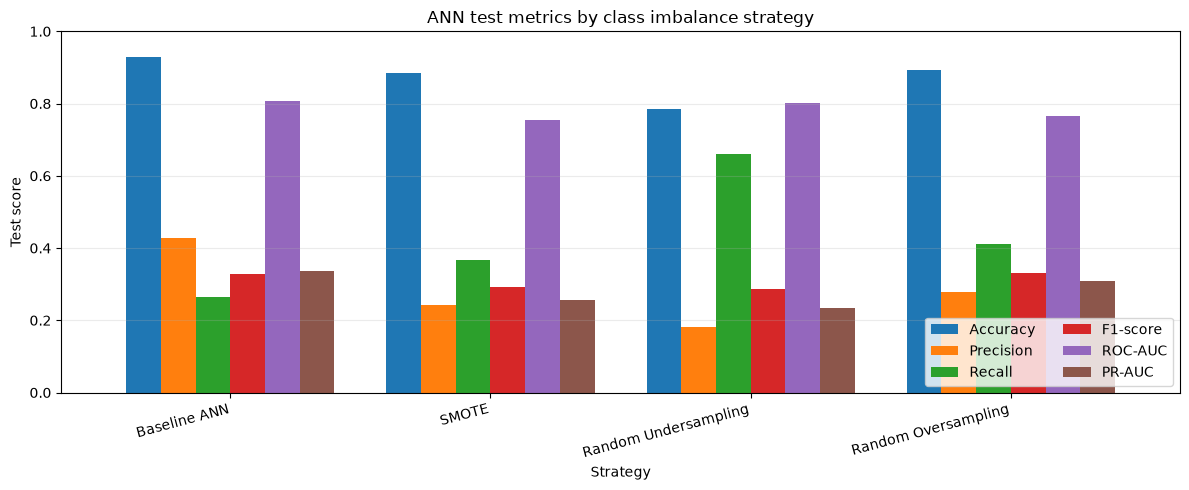

In [25]:
ax = comparison[metric_names].plot(kind="bar", figsize=(12, 5), ylim=(0, 1), width=0.8)
ax.set(ylabel="Test score", title="ANN test metrics by class imbalance strategy")
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower right", ncol=2)
plt.tight_layout()
plt.show()

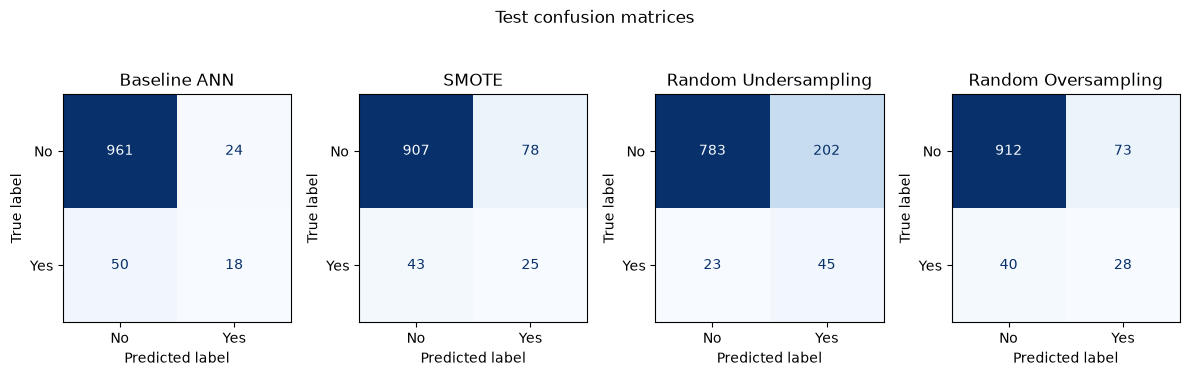

In [26]:
fig, axes = plt.subplots(1, len(results), figsize=(12, 3.8))
for ax, (name, result) in zip(axes, results.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=label_encoder.classes_,
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
fig.suptitle("Test confusion matrices")
fig.tight_layout()
plt.show()

### 9. Evaluation interpretation

Accuracy is not sufficient with 68 positive cases in the test set. Precision measures false-positive burden, recall measures detection of positive cases, and F1 balances the two for the positive class. ROC-AUC summarizes ranking across thresholds, while PR-AUC is more informative here because positive cases are rare.

## 8. Validation threshold selection

For each approach, thresholds are selected from validation F1, with the unchanged validation distribution used to assess each threshold. ROC-AUC and PR-AUC are threshold-independent ranking measures; the test set is not used to choose a threshold.

In [27]:
THRESHOLDS = np.round(np.arange(0.10, 0.901, 0.01), 2)
threshold_curves = {}
validation_comparison_rows = []

for approach, result in results.items():
    y_true = result["y_val_true"]
    y_prob = result["y_val_prob"]
    curve_rows = []
    for threshold in THRESHOLDS:
        y_pred = (y_prob >= threshold).astype(int)
        curve_rows.append({"Threshold": threshold, **calculate_metrics(y_true, y_pred, y_prob)})

    curve = pd.DataFrame(curve_rows)
    best = curve.loc[curve["F1-score"].idxmax()]
    result["optimal_threshold"] = float(best["Threshold"])
    result["validation_optimized_metrics"] = best.to_dict()
    threshold_curves[approach] = curve
    validation_comparison_rows.append({
        "Approach": approach,
        "Optimal threshold": best["Threshold"],
        **{metric: best[metric] for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]},
    })

In [28]:
validation_comparison = pd.DataFrame(validation_comparison_rows)
validation_metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
display(validation_comparison.style.format({
    "Optimal threshold": "{:.2f}",
    **{name: "{:.4f}" for name in validation_metric_names},
}))

,Approach,Optimal threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Baseline ANN,0.43,0.9288,0.4333,0.3171,0.3662,0.7686,0.2602
1,SMOTE,0.66,0.8956,0.2807,0.3902,0.3265,0.7327,0.2484
2,Random Undersampling,0.86,0.9003,0.3514,0.6341,0.4522,0.8317,0.2582
3,Random Oversampling,0.83,0.9193,0.3611,0.3171,0.3377,0.7809,0.3133


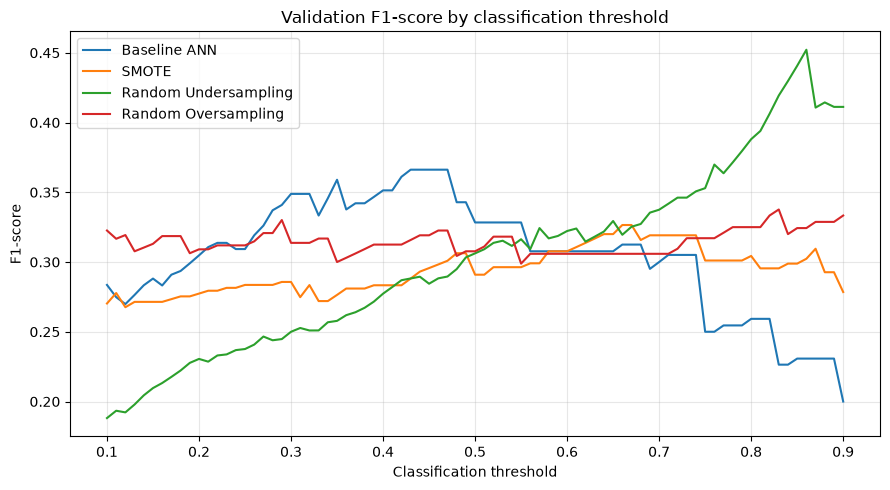

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
for approach, curve in threshold_curves.items():
    ax.plot(curve["Threshold"], curve["F1-score"], label=approach)
ax.set(title="Validation F1-score by classification threshold", xlabel="Classification threshold", ylabel="F1-score")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

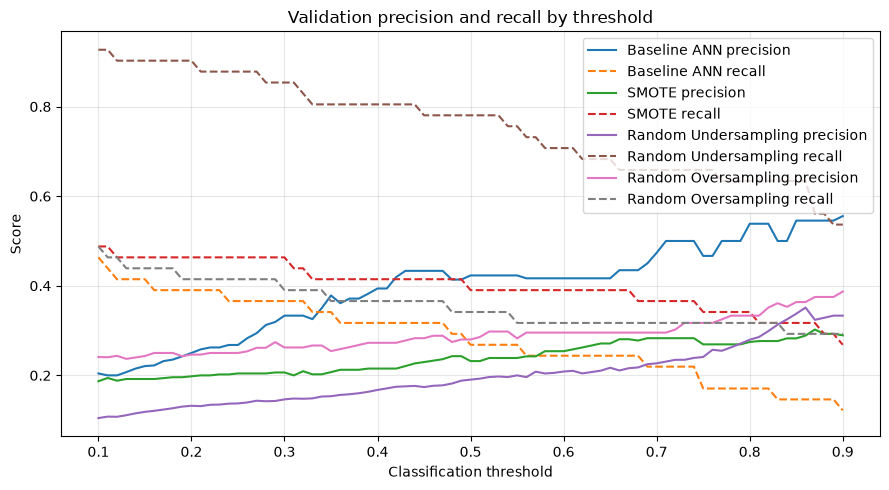

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))
for approach, curve in threshold_curves.items():
    ax.plot(curve["Threshold"], curve["Precision"], label=f"{approach} precision")
    ax.plot(curve["Threshold"], curve["Recall"], linestyle="--", label=f"{approach} recall")
ax.set(title="Validation precision and recall by threshold", xlabel="Classification threshold", ylabel="Score")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

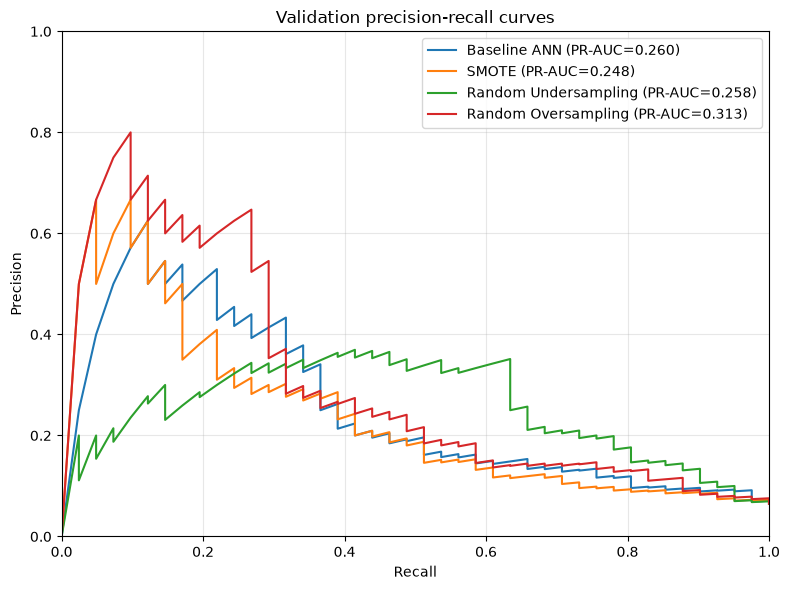

In [31]:
fig, ax = plt.subplots(figsize=(8, 6))
for approach, result in results.items():
    precision, recall, _ = precision_recall_curve(result["y_val_true"], result["y_val_prob"])
    ax.plot(recall, precision, label=f"{approach} (PR-AUC={result['validation_optimized_metrics']['PR-AUC']:.3f})")
ax.set(title="Validation precision-recall curves", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1))
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## 10. Final test evaluation

Default and validation-selected thresholds are evaluated on the untouched test set. Threshold-dependent metrics may change, but ROC-AUC and PR-AUC remain unchanged for a given model's probability ranking.

In [32]:
test_comparison_rows = []
for approach, result in results.items():
    y_true = result["y_true"]
    y_prob = result["y_prob"]
    result["test_metrics_default_threshold"] = calculate_metrics(y_true, (y_prob >= 0.50).astype(int), y_prob)
    result["test_metrics_optimized_threshold"] = calculate_metrics(
        y_true, (y_prob >= result["optimal_threshold"]).astype(int), y_prob
    )
    for threshold_name, threshold, metrics in [
        ("Default", 0.50, result["test_metrics_default_threshold"]),
        ("Validation optimized", result["optimal_threshold"], result["test_metrics_optimized_threshold"]),
    ]:
        test_comparison_rows.append({
            "Approach": approach,
            "Threshold selection": threshold_name,
            "Threshold": threshold,
            **metrics,
        })

test_comparison = pd.DataFrame(test_comparison_rows)
test_metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
display(test_comparison.style.format({
    "Threshold": "{:.2f}",
    **{name: "{:.4f}" for name in test_metric_names},
}))

,Approach,Threshold selection,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Baseline ANN,Default,0.50,0.9297,0.4286,0.2647,0.3273,0.8082,0.3367
1,Baseline ANN,Validation optimized,0.43,0.9269,0.4082,0.2941,0.3419,0.8082,0.3367
2,SMOTE,Default,0.50,0.8851,0.2427,0.3676,0.2924,0.7543,0.2571
3,SMOTE,Validation optimized,0.66,0.8955,0.2717,0.3676,0.3125,0.7543,0.2571
4,Random Undersampling,Default,0.50,0.7863,0.1822,0.6618,0.2857,0.8014,0.2346
5,Random Undersampling,Validation optimized,0.86,0.8851,0.2613,0.4265,0.3240,0.8014,0.2346
6,Random Oversampling,Default,0.50,0.8927,0.2772,0.4118,0.3314,0.7670,0.3076
7,Random Oversampling,Validation optimized,0.83,0.9193,0.3651,0.3382,0.3511,0.7670,0.3076


## 11. ANN architecture visualization

The displayed graph represents the shared baseline architecture. It uses 64 and 32 ReLU hidden units and ends in one sigmoid-interpreted output.

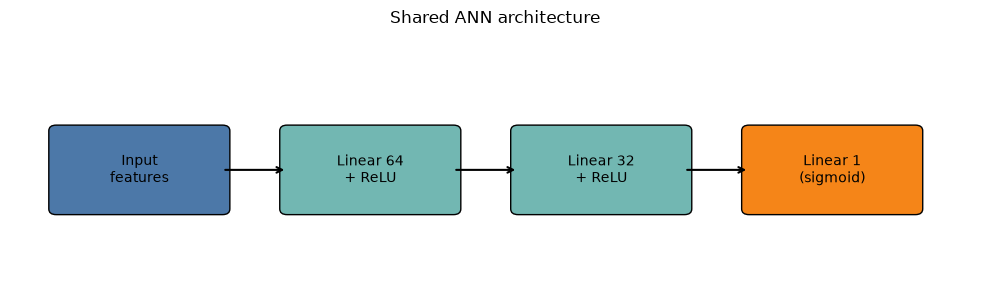

In [33]:
import matplotlib.patches as patches

model = results["Baseline ANN"]["model"]
fig, ax = plt.subplots(figsize=(10, 3))
layers = [
    ("Input\nfeatures", "#4C78A8"),
    ("Linear 64\n+ ReLU", "#72B7B2"),
    ("Linear 32\n+ ReLU", "#72B7B2"),
    ("Linear 1\n(sigmoid)", "#F58518"),
]
positions = [0.5, 3.0, 5.5, 8.0]
for (label, color), x in zip(layers, positions):
    ax.add_patch(patches.FancyBboxPatch(
        (x, 1.0), 1.8, 1.1,
        boxstyle="round,pad=0.08",
        facecolor=color,
        edgecolor="black",
    ))
    ax.text(x + 0.9, 1.55, label, ha="center", va="center", color="black")
for x1, x2 in zip(positions[:-1], positions[1:]):
    ax.annotate("", xy=(x2, 1.55), xytext=(x1 + 1.8, 1.55),
                arrowprops={"arrowstyle": "->", "lw": 1.5})
ax.set(xlim=(0, 10.5), ylim=(0, 3.5), title="Shared ANN architecture")
ax.axis("off")
plt.tight_layout()
plt.show()

## 12. Final analysis and conclusions

**Observed default-threshold results.** Random oversampling has the highest test F1-score at 0.3314, compared with 0.3273 for the baseline, 0.2924 for SMOTE, and 0.2857 for random undersampling. Oversampling also improves test recall from 0.2647 in the baseline to 0.4118, while precision falls from 0.4286 to 0.2772. Undersampling gives the largest default-threshold recall (0.6618), but precision is only 0.1822 and F1 remains 0.2857.

**Observed threshold-optimized results.** The validation-selected threshold of 0.83 gives random oversampling the strongest test F1-score in this run at 0.3511, versus 0.3419 for the baseline at threshold 0.43, 0.3125 for SMOTE at threshold 0.66, and 0.3240 for undersampling at threshold 0.86. Oversampling therefore provides the best positive-class balance in both threshold settings. Its test PR-AUC is 0.3076, however, below the baseline's 0.3367, so the F1 gain comes mainly from its positive-class weighting and threshold behavior rather than uniformly better probability ranking.

**Trade-offs and likely explanations.** Repeated minority observations expose the ANN to the positive class while preserving all majority observations. This is consistent with the observed recall improvement and better F1 than the baseline, but it does not improve precision as strongly as the baseline. SMOTE has lower test ROC-AUC (0.7543) and PR-AUC (0.2571) than the baseline and oversampling. Random undersampling discards most majority training observations, which explains its high sensitivity and larger false-positive burden.

**Best approach and limitations.** Based on test F1, random oversampling is the best strategy in the executed experiment. The validation-selected threshold 0.83 improves it from a default-threshold F1 of 0.3314 to 0.3511 on the test set. This conclusion is not based on accuracy alone. The main limitations are a single fixed split, no repeated cross-validation, no early-stopping or regularization search, and no comparison across random seeds. Random undersampling may also be sensitive to the particular majority observations discarded.

**Future work.** Add repeated stratified cross-validation, evaluate calibration and clinical-threshold costs, and tune architecture or regularization. Sampling variants and class-weighted loss should be compared while keeping preprocessing and test evaluation strictly separated.